# Задача 8: Определитель матрицы с комплексным параметром

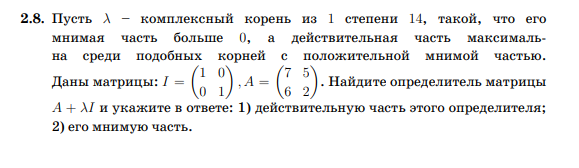

## Математическая база

### Корни n-й степени из единицы

Уравнение $z^n = 1$ имеет ровно $n$ корней:

$$\lambda_k = e^{2\pi i k / n} = \cos\frac{2\pi k}{n} + i\sin\frac{2\pi k}{n}, \quad k = 0, 1, \ldots, n-1$$

Все корни лежат на единичной окружности и образуют вершины правильного $n$-угольника.

### Определитель матрицы 2×2

$$\det\begin{pmatrix} a & b \\ c & d \end{pmatrix} = ad - bc$$

### Характеристический многочлен

$$\det(A + \lambda I) = \lambda^2 + \text{tr}(A)\lambda + \det(A)$$

---

## Решение

### Шаг 1. Найти λ

Корни 14-й степени из 1: $\lambda_k = e^{i\pi k/7}$, $k = 0, 1, \ldots, 13$.

Условие $\text{Im}(\lambda) > 0$ даёт $k \in \{1, 2, 3, 4, 5, 6\}$.

Максимум $\text{Re}(\lambda) = \cos(\pi k/7)$ достигается при $k = 1$:

$$\lambda = e^{i\pi/7} = \cos\frac{\pi}{7} + i\sin\frac{\pi}{7}$$

### Шаг 2. Определитель

$$A + \lambda I = \begin{pmatrix} 7+\lambda & 5 \\ 6 & 2+\lambda \end{pmatrix}$$

$$\det(A + \lambda I) = (7+\lambda)(2+\lambda) - 30 = \lambda^2 + 9\lambda - 16$$

### Шаг 3. Подстановка

$$\det = e^{i2\pi/7} + 9e^{i\pi/7} - 16$$

$$= \left(\cos\frac{2\pi}{7} + 9\cos\frac{\pi}{7} - 16\right) + i\left(\sin\frac{2\pi}{7} + 9\sin\frac{\pi}{7}\right)$$


  λ = e^(iπ/7) = 0.9009688679 + 0.4338837391i
  k = 1

  Матрица A + λI:
  [[7.900969+0.433884i,  5.000000+0.000000i],
   [6.000000+0.000000i,  2.900969+0.433884i]]

  det(A + λI) = -7.2677903870 + 4.6867851345i

  1) Re(det) = -7.267790
  2) Im(det) = 4.686785


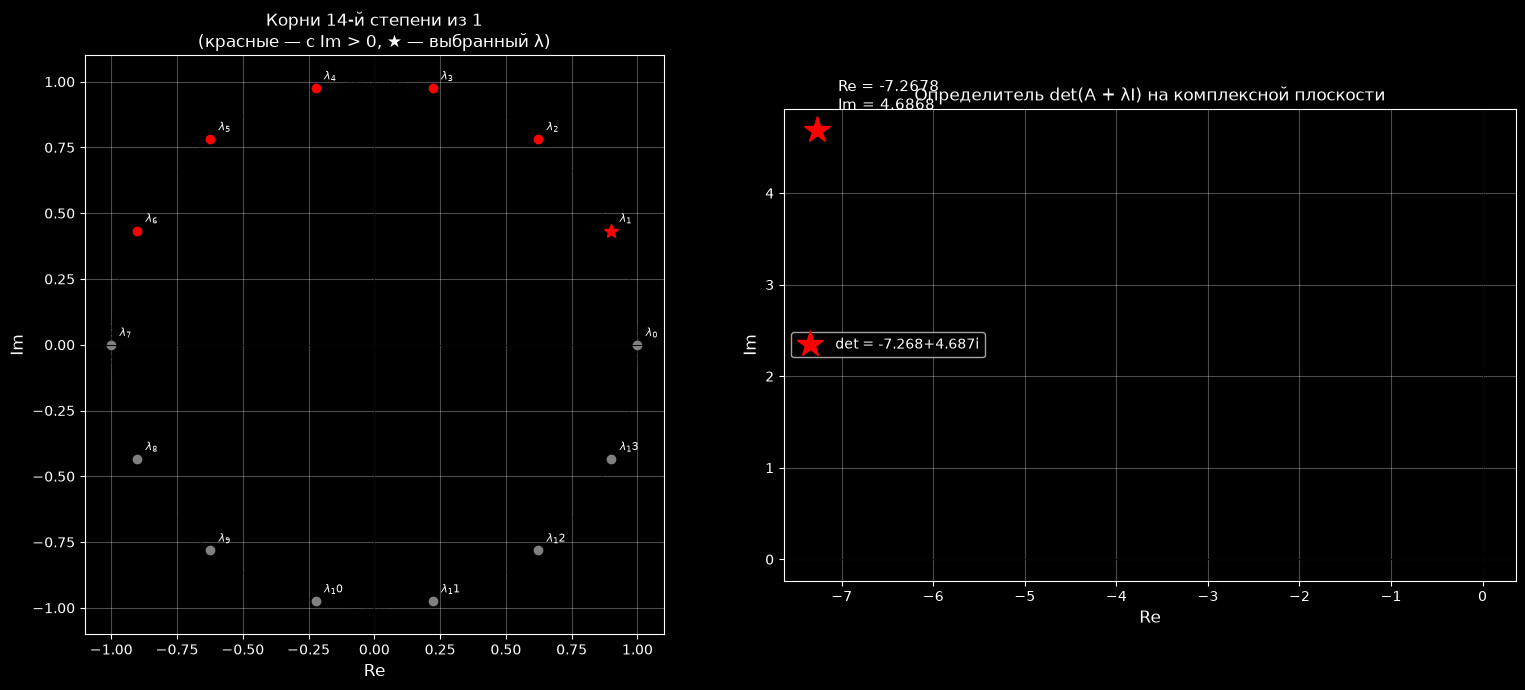

In [3]:
import numpy as np
import matplotlib.pyplot as plt


n = 14
roots = np.exp(2j * np.pi * np.arange(n) / n)

# Фильтруем корни с положительной мнимой частью
positive_im = roots[roots.imag > 1e-10]

# Выбираем корень с максимальной действительной частью
idx = np.argmax(positive_im.real)
lam = positive_im[idx]

print("=" * 60)
print(f"  λ = e^(iπ/7) = {lam.real:.10f} + {lam.imag:.10f}i")
print(f"  k = {np.argmax(roots.imag > 1e-10) if False else 1}")
print("=" * 60)


A = np.array([[7, 5], [6, 2]], dtype=complex)
I = np.eye(2, dtype=complex)

M = A + lam * I
det_val = np.linalg.det(M)

print(f"\n  Матрица A + λI:")
print(f"  [[{M[0,0].real:.6f}+{M[0,0].imag:.6f}i,  {M[0,1].real:.6f}+{M[0,1].imag:.6f}i],")
print(f"   [{M[1,0].real:.6f}+{M[1,0].imag:.6f}i,  {M[1,1].real:.6f}+{M[1,1].imag:.6f}i]]")

print(f"\n  det(A + λI) = {det_val.real:.10f} + {det_val.imag:.10f}i")
print("=" * 60)


print(f"\n  1) Re(det) = {det_val.real:.6f}")
print(f"  2) Im(det) = {det_val.imag:.6f}")
print("=" * 60)


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Левый график: все корни 14-й степени
theta = np.linspace(0, 2*np.pi, 300)
axes[0].plot(np.cos(theta), np.sin(theta), 'k--', linewidth=0.8, alpha=0.5)
for k in range(n):
    z = roots[k]
    color = 'red' if z.imag > 1e-10 else 'gray'
    marker = '*' if np.isclose(z, lam) else 'o'
    size = 150 if np.isclose(z, lam) else 60
    axes[0].plot(z.real, z.imag, marker, color=color, markersize=10 if np.isclose(z, lam) else 6)
    axes[0].annotate(f'$\\lambda_{k}$', (z.real, z.imag),
                     textcoords="offset points", xytext=(6, 6), fontsize=8)

axes[0].axhline(0, color='black', linewidth=0.7)
axes[0].axvline(0, color='black', linewidth=0.7)
axes[0].set_xlabel('Re', fontsize=12)
axes[0].set_ylabel('Im', fontsize=12)
axes[0].set_title('Корни 14-й степени из 1\n(красные — с Im > 0, ★ — выбранный λ)', fontsize=12)
axes[0].set_aspect('equal')
axes[0].grid(True, alpha=0.3)

# Правый график: det на комплексной плоскости
axes[1].plot(det_val.real, det_val.imag, 'r*', markersize=20, label=f'det = {det_val.real:.3f}+{det_val.imag:.3f}i')
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].axvline(0, color='black', linewidth=0.7)
axes[1].annotate(f'Re = {det_val.real:.4f}\nIm = {det_val.imag:.4f}',
                 (det_val.real, det_val.imag),
                 textcoords="offset points", xytext=(15, 15), fontsize=11)
axes[1].set_xlabel('Re', fontsize=12)
axes[1].set_ylabel('Im', fontsize=12)
axes[1].set_title('Определитель det(A + λI) на комплексной плоскости', fontsize=12)
axes[1].set_aspect('equal')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('task_2_8.png', dpi=150)
plt.show()